In [1]:
import os
import torch
os.environ["CUDA_VISIBLE_DEVICES"] = "3"  # Select the GPU index
device = 'cuda' if torch.cuda.is_available() else 'cpu'

import torch.nn.functional as F
from scipy.special import comb
import numpy as np
import math
from opt_einsum import contract   # This is for faster torch.einsum
from torch.autograd import Variable
from itertools import product
import matplotlib.pyplot as plt
from reed_muller_modules.hadamard import *

import spacy
from scipy.io import savemat
import dill as pickle

CUDA version of Hadamard transform isn't installed. Will use Pytorch's version, which is much slower.


In [2]:
def repetition_code_matrices(device, m=8):
    
    M_dict = {}
    
    for i in range(1, m):
        M_dict[i] = torch.ones(1, 2**i).to(device)
    
    return M_dict


In [3]:
def first_order_encoder_Plotkin(msg_bits, order_of_RM1):
    
    repetition_M_dict = repetition_code_matrices(device,order_of_RM1)
    u_level0 = msg_bits[:, 0:1]
    v_level0 = msg_bits[:, 1:2]
    
    for i in range(2, order_of_RM1+1):
        
        u_level0 = torch.cat([ u_level0,  u_level0 * v_level0], dim=1)
        v_level0 = msg_bits[:, i:i+1].mm(repetition_M_dict[i-1])
    u_levelm = torch.cat([u_level0, u_level0 * v_level0], dim=1)
    
    return u_levelm

In [4]:
def generate_indices(all_msg_bits):
    # Get the number of bits and total number of messages
    num_bits = all_msg_bits.shape[1]
    num_messages = all_msg_bits.shape[0]
    
    # Initialize the indices tensors
    MinusOneIdx = []
    PlusOneIdx = []
    
    # For each bit position
    for i in range(num_bits):
        # Find indices where the bit is -1 and 1
        minus_one = torch.where(all_msg_bits[:, i] == -1)[0]
        plus_one = torch.where(all_msg_bits[:, i] == 1)[0]
        
        MinusOneIdx.append(minus_one)
        PlusOneIdx.append(plus_one)
    
    # Convert lists to tensors
    MinusOneIdx = torch.stack(MinusOneIdx).to(all_msg_bits.device)
    PlusOneIdx = torch.stack(PlusOneIdx).to(all_msg_bits.device)
    
    return MinusOneIdx, PlusOneIdx

In [5]:
def rm_encoder_plotkin(msg_bits, r, m):
    if r == 0:
        out = msg_bits.repeat(1,2**m)  
        return  out 
    elif r==1:
        # Create a new tensor with the desired arrangement
        rearranged_msg_bits = torch.cat([
            msg_bits[:, 0:1],  # Keep the first element
            msg_bits[:, 1:].flip(1)  # Flip the rest of the elements
        ], dim=1)
        out = first_order_encoder_Plotkin(rearranged_msg_bits.to(device), m)
        return out
    elif r == m:
        k1=2**(m-1)
        u = rm_encoder_plotkin(msg_bits[:,:k1], r-1, m-1)
        v = rm_encoder_plotkin(msg_bits[:,k1:], r-1, m-1)
        out = torch.cat([u, (u * v)], dim=1)
        return out
    else:
        k1 = int(sum([comb(m-1, i) for i in range(r+1)]))
        k2 = int(sum([comb(m-1, i) for i in range(r)]))
        u = rm_encoder_plotkin(msg_bits[:,:k1], r, m-1)
        v = rm_encoder_plotkin(msg_bits[:,k1:], r-1, m-1)
        out = torch.cat([u, (u * v)], dim=1)
        return out

In [6]:
def snr_db2sigma(train_snr):
    return 10**(-train_snr*1.0/20)/math.sqrt(2)

In [7]:
def log_sum_exp1(LLR_vector):
    sum_vector = LLR_vector.sum(dim=1, keepdim=True)
    sum_concat = torch.cat([sum_vector, torch.zeros_like(sum_vector)], dim=1)
    return torch.logsumexp(sum_concat, dim=1)- torch.logsumexp(LLR_vector, dim=1) 

In [8]:
def llr_info_bits(hadamard_transform_llr, order_of_RM1): 
    first_order_Mul_Ind_Zero_dict, first_order_Mul_Ind_One_dict = first_order_Mul_matrices(device, order_of_RM1+1)
    max_1, _ = hadamard_transform_llr.max(1, keepdim=True)
    min_1, _ = hadamard_transform_llr.min(1, keepdim=True)
    LLR_zero_column = max_1 + min_1 

    # modify this tomorrow morning
    
    max_zero, _ = torch.max(contract('ij, kj ->  ikj', hadamard_transform_llr.abs() , first_order_Mul_Ind_Zero_dict[order_of_RM1]), 2)
    max_one, _ =  torch.max(contract('ij, kj ->  ikj', hadamard_transform_llr.abs() , first_order_Mul_Ind_One_dict[order_of_RM1]), 2)
    LLR_remaining = max_zero - max_one
    return torch.cat([LLR_zero_column, LLR_remaining], dim=1)

In [9]:
def bin_array(num, m):
    """Convert a positive integer num into an m-bit bit vector"""
    return np.array(list(np.binary_repr(num).zfill(m))).astype(np.float32).reshape(-1)

In [10]:
def FirstOrder_SoftFHT_InfoBits_decoder(llr, order_of_RM1):
    
    hadamard_transform_llr = hadamard_transform_torch(llr)  # shape (batch_size , 128)    
#     hadamard_transform_llr = hadamard_transform_cuda(llr)  # shape (batch_size , 128)    
    return llr_info_bits(hadamard_transform_llr, order_of_RM1) #     return  modified_llr_codeword(llr_info_bits(hadamard_transform_llr, m))

In [11]:
def RM_mm_SoftMAP_decoder(LLR, RM_mm_codebook_PlusOne, RM_mm_codebook_MinusOne):
    
    max_PlusOne, _ = torch.max(contract('lk, ijk ->  lij', LLR, RM_mm_codebook_PlusOne), 2)
    max_MinusOne, _ =  torch.max(contract('lk, ijk ->  lij', LLR, RM_mm_codebook_MinusOne), 2)
    
    return max_PlusOne - max_MinusOne

In [12]:
def rm_decoder_dumer(llr, r, m):
    n = 2**m
    if r == 0:
        decoded_message = torch.sign((torch.sum(llr, dim=1))).unsqueeze(1)
        decoded_codeword = decoded_message.repeat(1,2**m)
        return decoded_codeword, decoded_message
    elif r == 1:
        decoded_message = FirstOrder_SoftFHT_InfoBits_decoder(llr, m).sign()
        decoded_codeword = rm_encoder_plotkin(decoded_message, r, m)
        return decoded_codeword, decoded_message
    elif r == m:
        k = sum(math.comb(m, i) for i in range(r+1))
        all_msg_bits_mm_leaf = []
        msg_length = k  # Use actual message length instead of hardcoded 4
        
        for i in range(2**k-1, -1, -1):
            bits = bin_array(i, msg_length)  # Use proper message length
            all_msg_bits_mm_leaf.append(bits*2-1)
            
        all_msg_bits_mm_leaf = torch.tensor(np.array(all_msg_bits_mm_leaf)).to(device)
        MinusOneIdx_mm_leaf, PlusOneIdx_mm_leaf = generate_indices(all_msg_bits_mm_leaf)
        
        RM_mm_codebook = rm_encoder_plotkin(all_msg_bits_mm_leaf, r, m)
        RM_mm_codebook_PlusOne = RM_mm_codebook[PlusOneIdx_mm_leaf]
        RM_mm_codebook_MinusOne = RM_mm_codebook[MinusOneIdx_mm_leaf]
        
        decoded_message = RM_mm_SoftMAP_decoder(llr, RM_mm_codebook_PlusOne, RM_mm_codebook_MinusOne).sign()
        decoded_codeword = rm_encoder_plotkin(decoded_message, r, m)
        return decoded_codeword, decoded_message
    else:
        # Split LLR into two halves
        llr_left = llr[:, :n//2]
        llr_right = llr[:, n//2:]

        # Decode left child (v)
        llr_v = log_sum_exp1(torch.cat([llr_left.unsqueeze(2), llr_right.unsqueeze(2)], dim=2).permute(0, 2, 1))
        v_c, v_hat = rm_decoder_dumer(llr_v, r-1, m-1)
        
        # Compute LLR for right child (u)
        llr_u = llr_left + v_c * llr_right
        u_c, u_hat = rm_decoder_dumer(llr_u, r, m-1)
        
        # Combine decoded bits
        decoded_message = torch.cat([u_hat, v_hat], dim=1)
        decoded_codeword = torch.cat([u_c, (u_c*v_c)], dim=1)
        return decoded_codeword, decoded_message

In [13]:
def first_order_Mul_matrices(device, m =8):
    
    Mul_Ind_Zero_dict, Mul_Ind_One_dict = {}, {}
    
    for i in range(1, m):
        # ## Loading the Mul_matrices
        Mul_Ind_Zero_dict[i] = Variable(torch.load('./data/{0}/Mul_this_matrix_Ind_Zero.pt'.format( i if i>0 else 1))).to(device)
        Mul_Ind_One_dict[i] = Variable(torch.load('./data/{0}/Mul_this_matrix_Ind_One.pt'.format( i if i>0 else 1))).to(device)
        
    
    return Mul_Ind_Zero_dict, Mul_Ind_One_dict

# BER Simulation

In [14]:
r=4
m=9
batch_size = 2*10**3
k = sum(math.comb(m, i) for i in range(r+1)) # information length
N = 2**m  # codeword length   
num_examples = 10**7  # number of examples per SNR

# SNR
SNR_dB_start_Eb = -5
SNR_dB_stop_Eb = 4
SNR_points = 10
ebnodb = torch.linspace(SNR_dB_start_Eb, SNR_dB_stop_Eb, SNR_points)  # number of SNR points on x-axis
print(ebnodb)
R = k / N

tensor([-5., -4., -3., -2., -1.,  0.,  1.,  2.,  3.,  4.])


In [15]:
path_directory = f"Results/plotkin_RM_({r},{m})/"
# Check if "models" folder exists, create it if it doesn't
if not os.path.exists(path_directory):
    os.makedirs(path_directory)

In [16]:
bers_test =[]
blers_test =[]
for i in range(SNR_points):
    print(f'Running {i+1}/{SNR_points} SNR points: {ebnodb[i]} dB')
    #noise_sigma = EbNo2Sigma(R, ebnodb[i])
    noise_sigma = snr_db2sigma(ebnodb[i])
    total_bit_errors = 0
    total_block_errors = 0
    num_batch = num_examples // batch_size

    for num in range(num_batch):
        # Randomly generating message bits 
        msg = 2*torch.randint(0, 2, (batch_size, k), dtype=torch.float32).to(device)-1

        # Channel Coding
        channel_encoder_output = rm_encoder_plotkin(msg, r, m)

        # Channel
        noise = noise_sigma * torch.randn(batch_size, N).to(device)
        received_message = channel_encoder_output + noise

        # Compute LLRs
        llrs = (2/(noise_sigma**2))*received_message

        # Decoder
        decoded_codeword, msg_cap = rm_decoder_dumer(llrs, r, m)

        # Calculate bit errors
        bit_errors = torch.sum(msg != msg_cap, dim=1)
        total_bit_errors += bit_errors.sum().item()

        # Calculate block errors 
        block_errors = (bit_errors > 0).sum().item()
        total_block_errors += block_errors

    # Calculate final BER and BLER
    ber = total_bit_errors / (k * num_examples)
    bler = total_block_errors / num_examples

    print(f'BER: {ber:.6f}')
    print(f'BLER: {bler:.6f}')

    bers_test.append(ber)
    blers_test.append(bler)
print(bers_test)
print(f'blers_test: {blers_test}')

Running 1/10 SNR points: -5.0 dB
BER: 0.491808
BLER: 1.000000
Running 2/10 SNR points: -4.0 dB
BER: 0.489171
BLER: 1.000000
Running 3/10 SNR points: -3.0 dB
BER: 0.484912
BLER: 0.999914
Running 4/10 SNR points: -2.0 dB
BER: 0.470996
BLER: 0.992781
Running 5/10 SNR points: -1.0 dB
BER: 0.386912
BLER: 0.869707
Running 6/10 SNR points: 0.0 dB
BER: 0.165747
BLER: 0.415566
Running 7/10 SNR points: 1.0 dB
BER: 0.018525
BLER: 0.051965
Running 8/10 SNR points: 2.0 dB
BER: 0.000235
BLER: 0.000706
Running 9/10 SNR points: 3.0 dB
BER: 0.000000
BLER: 0.000000
Running 10/10 SNR points: 4.0 dB
BER: 0.000000
BLER: 0.000000
[0.4918080296875, 0.489171039453125, 0.4849118125, 0.470995643359375, 0.386912072265625, 0.165746734375, 0.01852510859375, 0.000235091015625, 7.4609375e-08, 0.0]
blers_test: [1.0, 0.9999999, 0.9999138, 0.9927811, 0.869707, 0.4155658, 0.0519652, 0.0007063, 3e-07, 0.0]


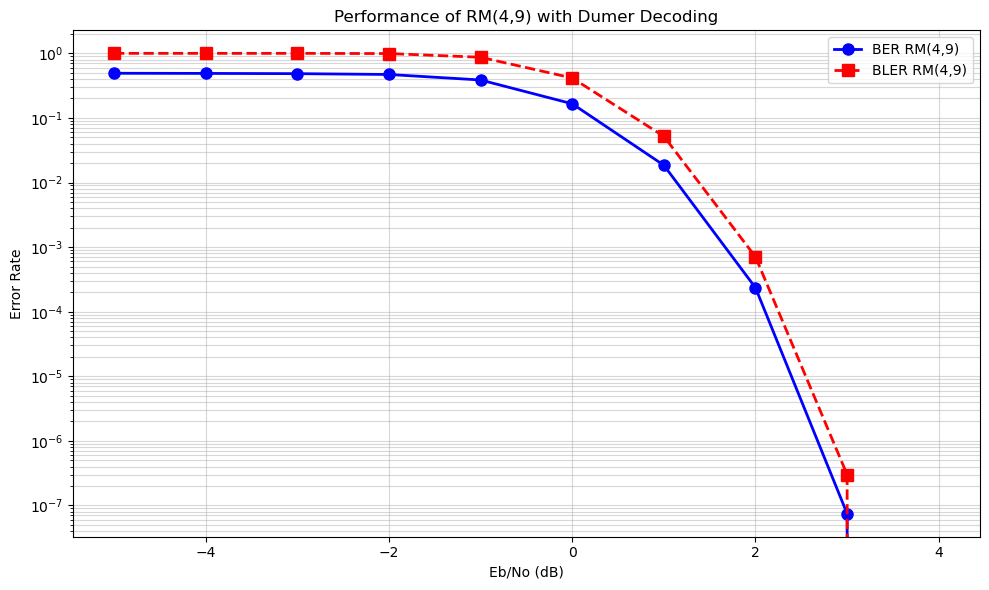

In [17]:
# Plotting BER curves
plt.figure(figsize=(10, 6))

# Plot BER
plt.semilogy(ebnodb.numpy(), bers_test, 'b-o', label=f'BER RM({r},{m})', linewidth=2, markersize=8)

# Plot BLER 
plt.semilogy(ebnodb.numpy(), blers_test, 'r--s', label=f'BLER RM({r},{m})', linewidth=2, markersize=8)

# Add grid
plt.grid(True, which="both", ls="-", alpha=0.5)

# Customize plot
plt.title(f'Performance of RM({r},{m}) with Dumer Decoding', fontsize=12)
plt.xlabel('Eb/No (dB)', fontsize=10)
plt.ylabel('Error Rate', fontsize=10)

# Add legend
plt.legend(fontsize=10)

# Adjust layout to prevent label clipping
plt.tight_layout()
# Save in multiple formats
#plt.savefig('rm_performance.eps', format='eps', dpi=300)  # EPS format
plt.savefig(path_directory+f'rm_performance({r},{m}).pdf', format='pdf', dpi=300)  # PDF format
#plt.savefig('rm_performance.png', format='png', dpi=300)  # PNG format

plt.show()

In [18]:
dict={'bers_test':bers_test,'blers_test':blers_test, 'snr_points':ebnodb.numpy(), 'r':r, 'm':m, 'num_examples':num_examples}

savemat(path_directory+f'berbler({r},{m}).mat', dict)
with open(path_directory+f'berbler({r},{m}).pkl', 'wb') as file:
    
    # A new file will be created
    pickle.dump(dict, file)